# Two-zone office building in Chur
## Dynamic thermal model, simulation and control

Valerio Paganini · dm4bem (Ch. Ghiaus), HS26 · December 2026

Report: <https://github.com/valPaga/eva-ce4ib-report>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from IPython.utils import io

with io.capture_output():                       # whole model and all simulations (Assignments 1, 2 and 4)
    %run Assignment4_Weather.ipynb
plt.rcParams.update({'font.size': 12, 'axes.grid': True, 'grid.alpha': 0.3})

## Building and hypotheses

- Single-storey office (SIA 2024 room type 3.01) above an unheated basement, 30 × 15 m
- Two zones of 225 m²: south and north, coupled by a concrete wall and a closed door
- Walls 0.20 m mineral wool + 0.20 m concrete, roof 0.16 m PUR + 0.28 m concrete, 60 % triple glazing, external blinds
- Weather Chur (TMYx 2004–2018), ventilation with heat recovery η = 0.75, set-points 21/26 °C occupied, 18/28 °C otherwise

In [2]:
display(SVG('figures/Assignment1_Model.drawio.svg'))

## Thermal network of zone 1

<div style="display:flex; gap:28px; align-items:center">
<img src="figures/Thermal_network_zone1.svg" style="height:540px">
<div style="font-size:0.75em">
<p>3 walls with windows, roof, floor and ventilation run from the outdoor (or basement) temperature to the air
node θ<sub>71</sub>.</p>
<p>Long-wave radiation between the inner surfaces goes to the star node θ<sub>rm</sub>.</p>
<p>At the air node: internal gains, air capacity and the P-controller K<sub>p</sub> with set-point T<sub>sp</sub>.</p>
<p>Zone 2 is the same; the zones are coupled through the concrete interior wall and the door.</p>
</div></div>

## External wall and window (south, zone 1)

<img src="figures/Thermal_network_wall.svg" style="width:100%">

Wall: outdoor temperature source, outdoor surface, insulation (2 meshes) and concrete (4 meshes) with capacities,
inner surface; convection to the air, long-wave radiation to $\theta_{rm}$; solar flow sources $\Phi_o$, $\Phi_i$.
Window: glass node with small capacity and absorbed solar $\Phi_a$.

## Thermal model

| | |
|---|---|
| temperature nodes | 155 |
| flow-rate branches | 191 |
| state variables (nodes with capacity) | 72 |
| inputs $u = [b_T^T, f_Q^T]^T$ | 20 + 28 = 48 |

Conduction, convection, long-wave radiation (star node), advection, P-controller.

$$C\dot\theta = -A^T G A\,\theta + A^T G\, b + f \quad\Longrightarrow\quad
\dot\theta_C = A_s \theta_C + B_s u, \qquad y = C_s \theta_C + D_s u$$

Steady state: DAE and state space agree to $10^{-12}$ °C; design heating load 5.5 kW per zone (24.6 W/m²) at −7.2 °C.

## Time constants, time step, settling time

In [3]:
def time_constants(Kp):
    G_K = G.copy()
    for k in k_ctrl:
        G_K[k, k] = Kp
    As = dm4bem.tc2ss(A, G_K, C, b_ptr, f_ptr, y_ptr)[0]
    T = -1 / np.linalg.eigvals(As).real
    return pd.Series({'smallest time constant': f'{T.min():.0f} s',
                      'largest time constant': f'{T.max() / 86400:.1f} d',
                      'Δt_max explicit Euler = 2 T_min': f'{2 * T.min():.0f} s',
                      'settling time ≈ 4 T_max': f'{4 * T.max() / 86400:.0f} d'})


pd.DataFrame({'free-floating (K_p = 0)': time_constants(0), 'P-controller (K_p = 10⁵ W/K)': time_constants(K_on)})

,free-floating (K_p = 0),P-controller (K_p = 10⁵ W/K)
smallest time constant,515 s,8 s
largest time constant,17.6 d,7.9 d
Δt_max explicit Euler = 2 T_min,1031 s,16 s
settling time ≈ 4 T_max,70 d,31 d


The P-controller adds a very fast mode (air node), so explicit Euler would need Δt < 16 s.
The year is simulated with **implicit Euler, Δt = 15 min**, after a 30-day warm-up.

## Inputs: one year of weather in Chur

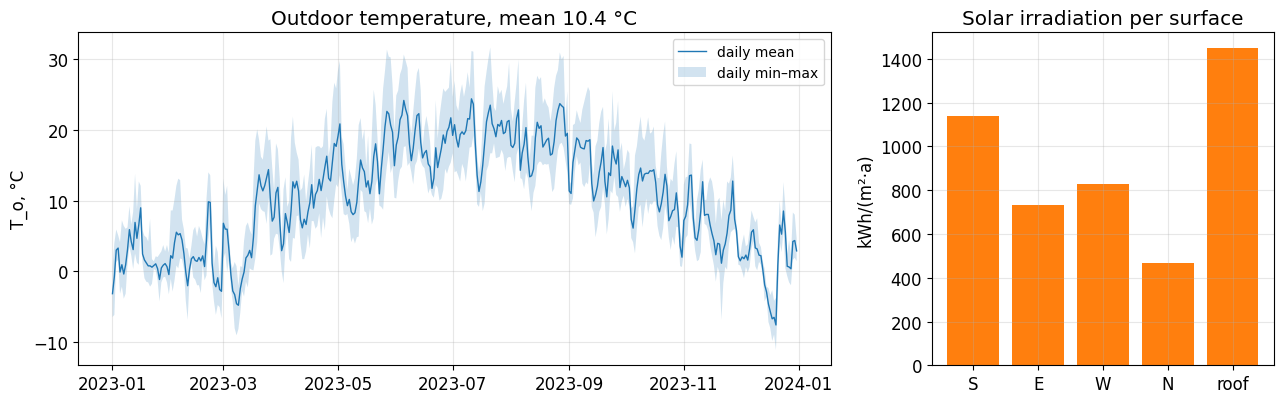

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
To = weather['T_o']
axs[0].plot(To.resample('D').mean(), lw=1, label='daily mean')
axs[0].fill_between(To.resample('D').min().index, To.resample('D').min(), To.resample('D').max(), alpha=0.2,
                    label='daily min–max')
axs[0].set(ylabel='T_o, °C', title=f'Outdoor temperature, mean {To.mean():.1f} °C')
axs[0].legend(fontsize=10)
irr = weather.filter(like='E_').sum() / 1000
axs[1].bar([c[2:] for c in irr.index], irr, color='tab:orange')
axs[1].set(ylabel='kWh/(m²·a)', title='Solar irradiation per surface')
plt.tight_layout()
plt.show()

Internal gains (SIA 2024) 58.7 kWh/(m²·a); blinds closed above 200 W/m² on the façade in summer.

## Controllers: P, dead-band and ventilation

In [5]:
cases = {'P-controller': 'P', 'dead-band': 'dead-band', '+ bypass, night ventilation': 'dead-band + ventilation'}
rows = ['heating, kWh/m²', 'cooling, kWh/m²', 'peak heating (sum of zones), W/m²', 'peak cooling (sum of zones), W/m²']
tab = pd.DataFrame({k: key_figures(res[v]) for k, v in cases.items()}).loc[rows]
tab.index = ['heating, kWh/(m²·a)', 'cooling, kWh/(m²·a)', 'peak heating, W/m²', 'peak cooling, W/m²']
tab.round(1)

,P-controller,dead-band,"+ bypass, night ventilation"
"heating, kWh/(m²·a)",11.8,6.9,7.0
"cooling, kWh/(m²·a)",65.7,23.9,7.3
"peak heating, W/m²",39.1,38.6,38.6
"peak cooling, W/m²",39.4,33.7,26.9


- A single P-controller heats and cools to the same set-point: 66 kWh/(m²·a) cooling
- Dead-band: 6.9 / 23.9 kWh/(m²·a), SIA 2024 gives 8.1 / 12.4
- Heat-recovery bypass and night ventilation (2 h⁻¹ by windows): cooling −70 %

## A summer week

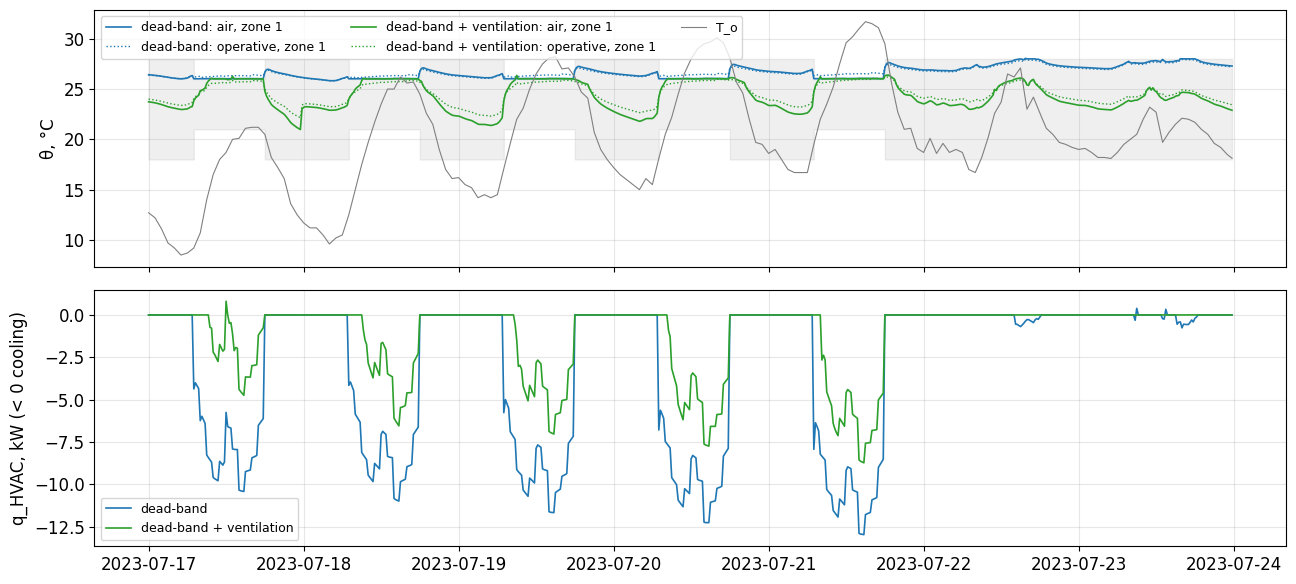

In [6]:
a, b = weeks['summer week']
fig, axs = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for c, color in (('dead-band', 'tab:blue'), ('dead-band + ventilation', 'tab:green')):
    r = res[c].loc[a:b]
    axs[0].plot(r.index, r['θ1'], color=color, lw=1.2, label=f'{c}: air, zone 1')
    axs[0].plot(r.index, r['θop1'], color=color, lw=1, ls=':', label=f'{c}: operative, zone 1')
    axs[1].plot(r.index, r[['q1', 'q2']].sum(axis=1) / 1000, color=color, lw=1.2, label=c)
r = res['dead-band'].loc[a:b]
axs[0].fill_between(r.index, r['T_h'], r['T_c'], color='grey', alpha=0.12, step='post')
axs[0].plot(w.loc[a:b, 'T_o'], color='grey', lw=0.8, label='T_o')
axs[0].set(ylabel='θ, °C')
axs[1].set(ylabel='q_HVAC, kW (< 0 cooling)')
axs[0].legend(fontsize=9, ncol=3, loc='upper left')
axs[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Night air cools the concrete; the stored cold takes up the gains of the next day.

## Optimization

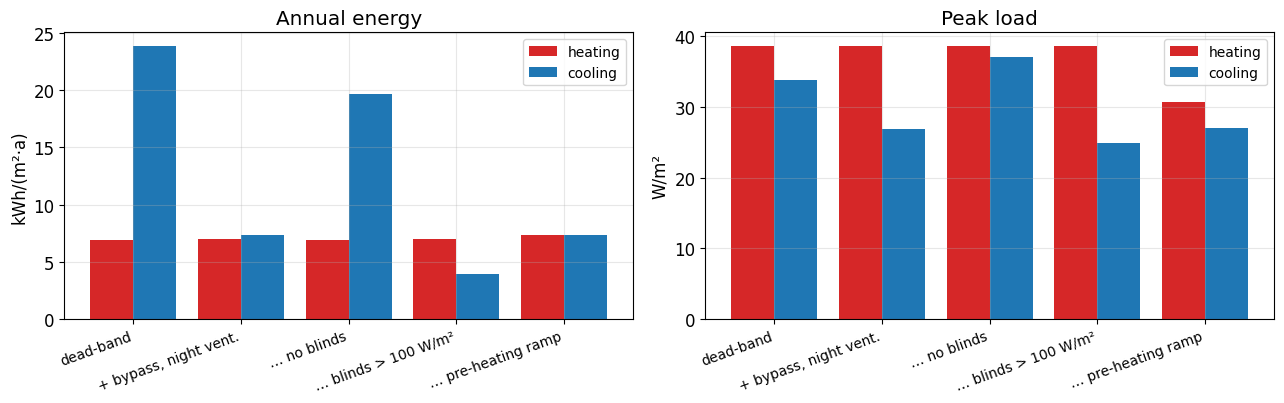

In [7]:
var = {'dead-band': key_figures(res['dead-band']),
       '+ bypass, night vent.': key_figures(res['dead-band + ventilation']),
       '… no blinds': opt['no blinds'],
       '… blinds > 100 W/m²': opt['blinds > 100 W/m²'],
       '… pre-heating ramp': key_figures(res['dead-band + ventilation + pre-heating'])}
V = pd.DataFrame(var)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(V.columns))
axs[0].bar(x - 0.2, V.loc['heating, kWh/m²'], 0.4, color='tab:red', label='heating')
axs[0].bar(x + 0.2, V.loc['cooling, kWh/m²'], 0.4, color='tab:blue', label='cooling')
axs[0].set(ylabel='kWh/(m²·a)', title='Annual energy')
axs[1].bar(x - 0.2, V.loc['peak heating (sum of zones), W/m²'], 0.4, color='tab:red', label='heating')
axs[1].bar(x + 0.2, V.loc['peak cooling (sum of zones), W/m²'], 0.4, color='tab:blue', label='cooling')
axs[1].set(ylabel='W/m²', title='Peak load')
for ax in axs:
    ax.set_xticks(x, V.columns, rotation=20, ha='right', fontsize=10)
    ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

- Blinds: without them cooling ×2.7; at 100 W/m² −47 %, but closed ~1600 h/a on every façade
- Pre-heating ramp 18 → 21 °C from 05:00: peak heating −20 % for +0.3 kWh/(m²·a)

## Model predictive control (winter week)

In [8]:
a, b = weeks['winter week']
mp = pd.DataFrame({c: key_figures(r.loc[a:b]) for c, r in res_w.items()}).loc[
    ['heating, kWh', 'peak heating (sum of zones), W/m²']]
mp.index = ['heating, kWh', 'peak heating, W/m²']
mp.round(1)

,dead-band,"MPC, energy","MPC, energy + peak"
"heating, kWh",153.1,154.1,162.2
"peak heating, W/m²",27.1,27.7,17.9


Linear program every hour over 24 h, perfect forecast, $\theta_{air} = \theta_{free} + H q$:

$$\min \sum (q_h + q_c)\,\Delta t + \lambda\,(\hat q_h + \hat q_c) + \rho \sum s
\qquad T_h - s \le \theta_{air} \le T_c + s$$

- Energy only: same as dead-band (both heat as late as possible)
- With peak cost λ = 4 kWh/kW: pre-heats into the mass, peak −34 % for +6 % energy

## Comfort and load duration

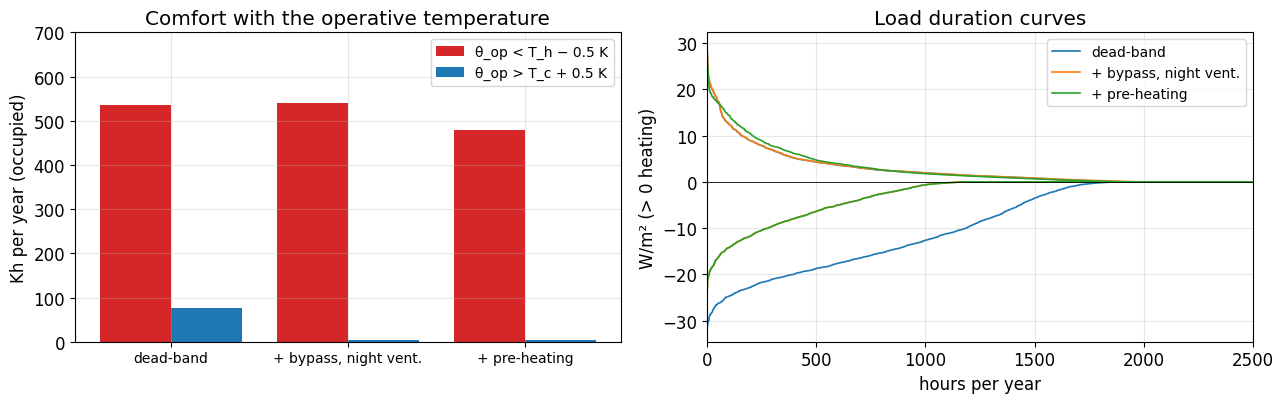

In [9]:
cs = ['dead-band', 'dead-band + ventilation', 'dead-band + ventilation + pre-heating']
lab = ['dead-band', '+ bypass, night vent.', '+ pre-heating']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
K = pd.DataFrame({l: key_figures(res[c]) for c, l in zip(cs, lab)})
x = np.arange(3)
axs[0].bar(x - 0.2, K.loc['under-heating θ_op, Kh'], 0.4, color='tab:red', label='θ_op < T_h − 0.5 K')
axs[0].bar(x + 0.2, K.loc['over-heating θ_op, Kh'], 0.4, color='tab:blue', label='θ_op > T_c + 0.5 K')
axs[0].set_xticks(x, lab, fontsize=10)
axs[0].set(ylabel='Kh per year (occupied)', title='Comfort with the operative temperature', ylim=(0, 700))
axs[0].legend(fontsize=10, loc='upper right')
for c, l in zip(cs, lab):
    qh = res[c][['q1', 'q2']].sum(axis=1).resample('h').mean() / S_tot
    line, = axs[1].plot(np.sort(qh.clip(lower=0).to_numpy())[::-1], lw=1.2, label=l)
    axs[1].plot(np.sort(qh.clip(upper=0).to_numpy()), lw=1.2, color=line.get_color())
axs[1].axhline(0, color='k', lw=0.6)
axs[1].set(xlim=(0, 2500), xlabel='hours per year', ylabel='W/m² (> 0 heating)', title='Load duration curves')
axs[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

The air stays within the set-points, the operative temperature does not: cold walls on winter mornings.

## Conclusions

- 155-node model of a two-zone building, solved as state space with 72 states; implicit Euler, Δt = 15 min
- Dead-band: 6.9 kWh/(m²·a) heating, 23.9 cooling; with bypass and night ventilation 7.3 cooling (+0.4 latent)
- Largest levers: blinds and night ventilation (cooling), pre-heating or MPC (peak heating)
- Limits: ideal controllers, perfect forecast, constant $F_{sol}$ (no real horizon), constant surface
  coefficients, no sky radiation, one typical year

**Thank you – questions?**

## Backup: humid air

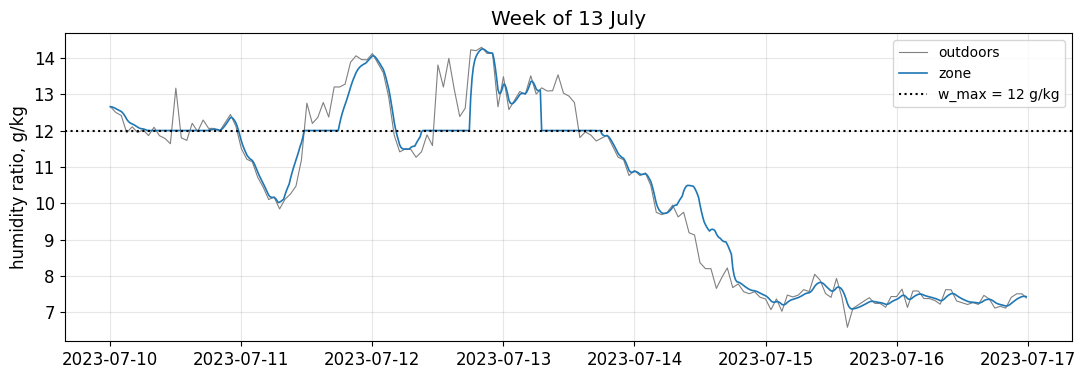

In [10]:
d0 = hum['dead-band + ventilation']['q_lat'].resample('D').sum().idxmax()
a, b = d0 - pd.Timedelta(days=d0.dayofweek), d0 + pd.Timedelta(days=6 - d0.dayofweek, hours=23.75)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(w.loc[a:b, 'w_o'] * 1e3, color='grey', lw=0.8, label='outdoors')
ax.plot(hum['dead-band + ventilation'].loc[a:b, 'w'] * 1e3, lw=1.2, label='zone')
ax.axhline(w_max * 1e3, color='k', ls=':', label='w_max = 12 g/kg')
ax.set(ylabel='humidity ratio, g/kg', title=f'Week of {d0:%d %B}')
ax.legend(fontsize=10)
plt.show()

Moisture balance per zone, 60 g/h per person, dehumidification to 12 g/kg during occupancy:
0.4 kWh/(m²·a) latent cooling. Outdoor air above 12 g/kg only 348 h a year.

## Backup: numerics and checks

- Time step: 5 min instead of 15 min changes the weekly energy by < 1 %, the air temperature by ≤ 0.4 K
- Explicit Euler with the P-controller: stable below 16 s, diverges at 16.8 s (Assignment 3)
- Steady state checks: all sources = 1 gives θ = 1 everywhere; DAE = state space to $10^{-12}$ °C
- Solar time correction: sun position at mid-hour in solar time (52 min in Chur); without it east −37 %,
  west +35 % direct radiation
- Ventilation modes and controller states switch the model: 3 × 4 = 12 discretised models